# Story 4: How Much Do We Get Paid?
**DATA 608 | Muhammad Suffyan Khan**

Source: BLS OEWS May 2025, published salary numbers transcribed via the six cited SignalBleed occupation pages. Annual **mean** wages, USD.

The 16-state matrix is a selected-state comparison, not a nationally representative mean. Missing values remain missing.

In [1]:
from pathlib import Path
import pandas as pd, numpy as np, matplotlib.pyplot as plt
from IPython.display import display
ROOT = Path.cwd()
if not (ROOT / "data").exists(): ROOT = ROOT.parent
a = pd.read_csv(ROOT / "data/processed/salary_16_states_6_occupations.csv")
b = pd.read_csv(ROOT / "data/processed/data_scientist_49_jurisdictions.csv")
print("Matrix rows:", len(a), "jurisdictions:", a.state.nunique(), "occupations:", a.occupation.nunique())
print("Missing observations:", a.annual_mean_usd.isna().sum())
print("Data scientist jurisdictions:", len(b))
assert len(a)==96 and len(b)==49 and a.annual_mean_usd.isna().sum()==1

Matrix rows: 96 jurisdictions: 16 occupations: 6
Missing observations: 1
Data scientist jurisdictions: 49


## Analysis 1: Occupation comparison
Equal-state average of published state annual mean wages in our 16-state sample. This is NOT the national BLS mean.

,mean_selected_state_wage_usd
occupation,
Operations Research Analysts,105908.000
Database Administrators,112745.625
Statisticians,115715.000
Computer Systems Analysts,118066.875
Data Scientists,127531.875
Database Architects,142458.750


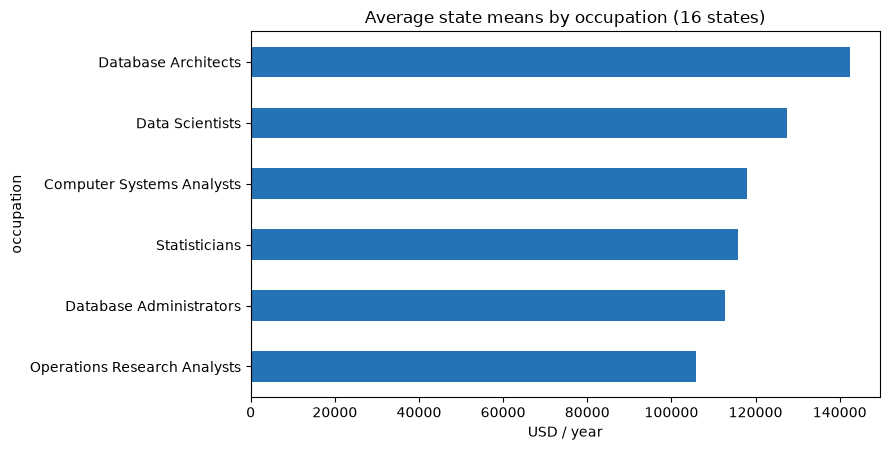

In [2]:
means = a.groupby("occupation").annual_mean_usd.mean().sort_values()
display(means.to_frame("mean_selected_state_wage_usd"))
means.plot.barh(figsize=(9,4.6),title="Average state means by occupation (16 states)",color="#2474B5"); plt.xlabel("USD / year"); plt.tight_layout();plt.show()

## Analysis 2: Joint state × occupation comparison
Use a shared color scale; suppressed/unpublished estimates must remain missing.

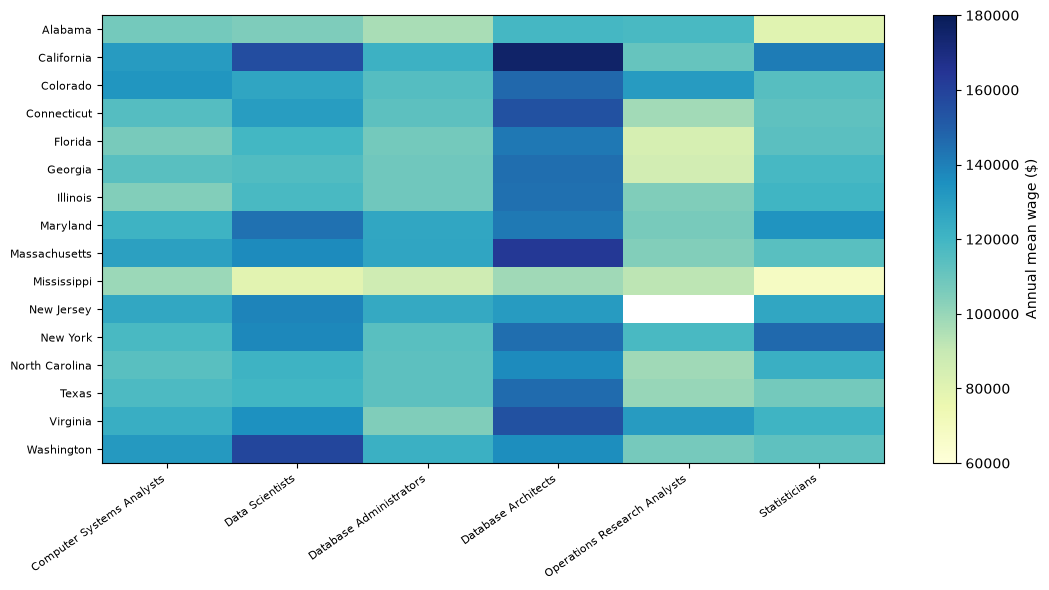

In [3]:
matrix=a.pivot(index="state",columns="occupation",values="annual_mean_usd")
fig,ax=plt.subplots(figsize=(11,6));p=ax.imshow(np.ma.masked_invalid(matrix.to_numpy()),aspect="auto",cmap="YlGnBu",vmin=60000,vmax=180000);ax.set_yticks(range(len(matrix)),matrix.index,fontsize=8);ax.set_xticks(range(len(matrix.columns)),matrix.columns,rotation=35,ha="right",fontsize=8);fig.colorbar(p,ax=ax,label="Annual mean wage ($)");plt.tight_layout();plt.show()

## Analysis 3: Geographic extremes for the same occupation
The additional data scientist file contains 49 published jurisdictions. This plot displays seven highest and seven lowest.

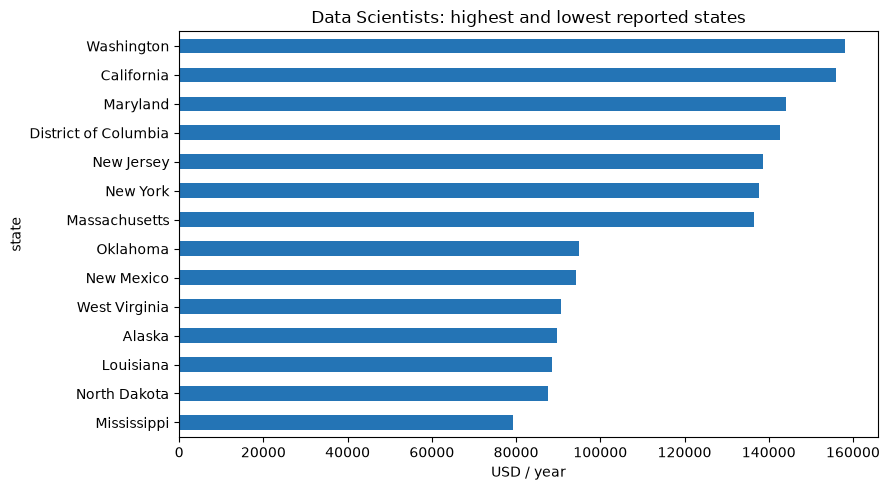

In [4]:
rank=b.sort_values("annual_mean_usd");tails=pd.concat([rank.head(7),rank.tail(7)]);tails.set_index("state").annual_mean_usd.plot.barh(figsize=(9,5),title="Data Scientists: highest and lowest reported states",color="#2474B5");plt.xlabel("USD / year");plt.tight_layout();plt.show()

## Analysis 4: Within-state salary difference
Signs may reverse; zero is a meaningful reference.

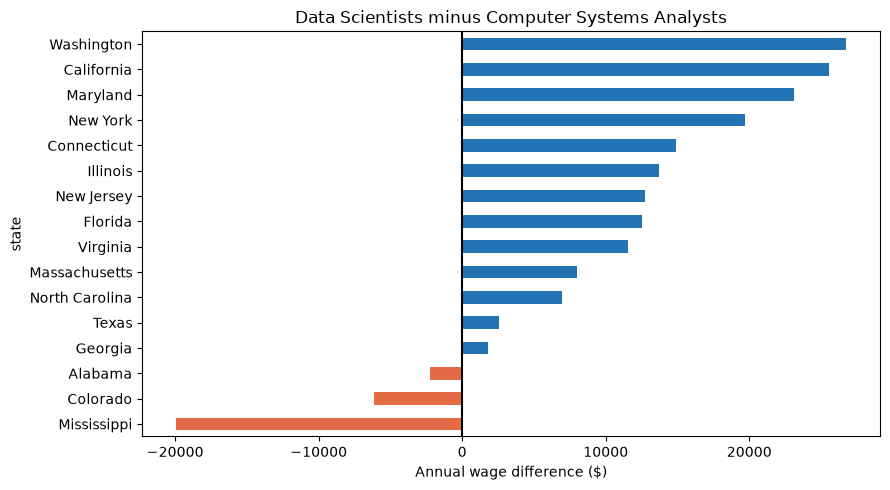

In [5]:
gap=(matrix["Data Scientists"]-matrix["Computer Systems Analysts"]).sort_values();gap.plot.barh(figsize=(9,5),color=["#E46B44" if v<0 else "#2474B5" for v in gap],title="Data Scientists minus Computer Systems Analysts");plt.axvline(0,color="black");plt.xlabel("Annual wage difference ($)");plt.tight_layout();plt.show()

## Conclusion
- Wage variation appears in both occupation and geography.
- The highest selected-state average among the six categories is Database Architects.
- Data Scientist mean wages range from $79,290 (Mississippi) to $158,040 (Washington) among published jurisdictions.
- Within-state differences between Data Scientists and Computer Systems Analysts do not have a consistent sign.

**Caution:** Wage statistics are not adjusted for cost of living; category definitions are not exact equivalents of informal job titles.